## Churn Analysis and Customer Intelligence

In [1]:
# import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

In [2]:
import warnings
warnings.filterwarnings('ignore')

## 1. Import database / data  

In [3]:
# Excel file path
excel_file = 'G:\Data Science Project\Python EDA Workshop\Customer Churn Analysis Using Python And SQL (25.09.26)\customer_churn_raw_data_final.xlsx'

# Create SQLite database connection
conn = sqlite3.connect('customer_churn.db')

# Read all sheet names from Excel file
excel_data = pd.ExcelFile(excel_file)

# Loop through each sheet and store as separate table
for sheet in excel_data.sheet_names:
    df = pd.read_excel(excel_file, sheet_name=sheet) # Read sheet into dataframe
    # Write dataframe to SQLite table
    df.to_sql(
        name=sheet,          # Table name = Sheet name
        con=conn,
        if_exists='replace', # Replace table if already exists
        index=False
    )

# Close connection
conn.close()

print("All sheets successfully converted into SQLite tables.")

All sheets successfully converted into SQLite tables.


In [4]:
# Data Import: db file to pandas, storing each table to a separate df

# Connect to SQLite database
conn = sqlite3.connect('customer_churn.db')

# sql query to Get all table names
sql_query = """
        SELECT name
        FROM sqlite_master
        WHERE type = 'table';
"""

# read sql query in pandas
tables = pd.read_sql(sql_query, conn)

# create dataframe for each table
for table_name in tables['name']:
    df = pd.read_sql(f"SELECT * FROM {table_name}", conn) # Read table into dataframe
    globals()[f"df_{table_name}"] = df                    # Create dynamic dataframe name
    print(f"Created dataframe: df_{table_name}")

# Close connection
conn.close()

Created dataframe: df_db_customer
Created dataframe: df_db_subscription
Created dataframe: df_db_support


In [5]:
# Print table names and column names
conn = sqlite3.connect('customer_churn.db')

for table_name in tables['name']:
    print(f"\nTable Name: {table_name}")
    # Get column information
    columns_query = f"PRAGMA table_info({table_name});"
    columns = pd.read_sql(columns_query, conn)
    print("Columns:")
    print(columns['name'].tolist())

# Close connection
conn.close()


Table Name: db_customer
Columns:
['Customerid', 'Name', 'Country', 'State', 'Gender', 'Dob', 'Interests', 'Pincode']

Table Name: db_subscription
Columns:
['Customerid', 'Subscription_Start_Date', 'Subscription_Type', 'Renewal_Date', 'Plan_Type', 'Contract_Type', 'Cancellation_Date', 'Cancellation_Reason', 'Monthly_Charges', 'Cltv', 'Churn_Score']

Table Name: db_support
Columns:
['Customerid', 'Complaint_Date', 'Escalations', 'Csat_Score', 'Col_1', 'Comment']


### PRAGMA is a special command in SQLite used to:
### inspect db information, control db settings, retrieve metadata about tables

## 2. Data Cleaning

In [6]:
df_db_customer.head()

,Customerid,Name,Country,State,Gender,Dob,Interests,Pincode
0,0002-AABMM,rishita,Nepal,Madhesh,Male,1966-02-24 00:00:00,news,None
1,0039-AABMN,asad,UK,Scotland,Women,1997-10-09 00:00:00,music,None
2,0076-AABMO,mira,Canada,British Columbia,Male,1988-12-15 00:00:00,drama,None
3,0113-AABMP,jack,USA,Florida,Female,1994-02-25 00:00:00,movie,None
4,0150-AABMQ,mohan,India,Nagaland,Female,2005-06-04 00:00:00,travel,None


In [7]:
df_db_customer.tail()

,Customerid,Name,Country,State,Gender,Dob,Interests,Pincode
199995,9817-ALLIP,rajesh,USA,Illinois,Women,1960-12-11 00:00:00,music,None
199996,9854-ALLIQ,emma,USA,Washington,Male,1997-05-01 00:00:00,fitness,None
199997,9891-ALLIR,james,India,Nagaland,Female,1981-05-11 00:00:00,travel,None
199998,9928-ALLIS,layla,USA,Florida,Female,1998-12-20 00:00:00,movie,None
199999,9965-ALLIT,evelyn,India,Delhi,Female,2001-06-02 00:00:00,job,None


In [8]:
df_db_customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200000 entries, 0 to 199999
Data columns (total 8 columns):
 #   Column      Non-Null Count   Dtype 
---  ------      --------------   ----- 
 0   Customerid  200000 non-null  object
 1   Name        200000 non-null  object
 2   Country     184020 non-null  object
 3   State       200000 non-null  object
 4   Gender      200000 non-null  object
 5   Dob         200000 non-null  object
 6   Interests   184093 non-null  object
 7   Pincode     0 non-null       object
dtypes: object(8)
memory usage: 12.2+ MB


### a. Change Columns Datatype

In [9]:
df_db_customer['Dob'] = pd.to_datetime(df_db_customer['Dob'])

### b. Fill Null Values

In [10]:
df_db_customer[df_db_customer["Country"].isna()]

,Customerid,Name,Country,State,Gender,Dob,Interests,Pincode
24,0890-AABNK,tania,None,Sylhet,Male,1963-11-26,drama,None
41,1519-AABOB,nisha,None,Sylhet,Male,1977-03-20,sports,None
44,1630-AABOE,karan,None,Delhi,Female,1971-07-12,fitness,None
46,1704-AABOG,radha,None,Telangana,Male,2005-11-11,drama,None
65,2407-AABOZ,henry,None,Sylhet,Women,1975-10-18,drama,None
...,...,...,...,...,...,...,...,...
199932,7486-ALLGE,jackson,None,Meghalaya,Male,1972-03-04,movie,None
199934,7560-ALLGG,sudevi,None,Florida,Women,1982-11-10,travel,None
199942,7856-ALLGO,mina,None,Uttar Pradesh,Male,1989-08-12,news,None
199952,8226-ALLGY,radha,None,Western Australia,Male,1963-08-02,None,None


In [11]:
df_db_customer[["Country", "State"]]

,Country,State
0,Nepal,Madhesh
1,UK,Scotland
2,Canada,British Columbia
3,USA,Florida
4,India,Nagaland
...,...,...
199995,USA,Illinois
199996,USA,Washington
199997,India,Nagaland
199998,USA,Florida


In [12]:
# Country and States unique value pair
state_country_mapping = df_db_customer.dropna(subset = ["Country"]).set_index("State")["Country"].to_dict()

In [13]:
df_db_customer["Country"] = df_db_customer["Country"].fillna(df_db_customer["State"].map(state_country_mapping))

### c. Remove Interest and Pincode column

In [14]:
 df_db_customer.drop(['Interests', 'Pincode'], axis = 1, inplace = True)

### d. Rename Column Names

In [15]:
df_db_customer.rename(columns = {'Name' : 'Customer_name'}, inplace = True)

### e. Data standardization

In [16]:
df_db_customer["Gender"].replace({'Men':'Male', 'Women':'Female'}, inplace = True)

In [17]:
df_db_customer["Gender"].unique()

array(['Male', 'Female'], dtype=object)

In [18]:
df_db_subscription.head()

,Customerid,Subscription_Start_Date,Subscription_Type,Renewal_Date,Plan_Type,Contract_Type,Cancellation_Date,Cancellation_Reason,Monthly_Charges,Cltv,Churn_Score
0,3999-AEUJX,2023-09-09 00:00:00,Paid,2023-10-02 00:00:00,Basic,Monthly,None,None,8.48,1057,0
1,3119-ACSUB,2022-02-24 00:00:00,Paid,2022-09-13 00:00:00,Premium,Annual,None,None,33.89,9996,0
2,4009-ADQKH,2023-10-25 00:00:00,Paid,2023-12-10 00:00:00,Basic,Monthly,2024-02-29 00:00:00,Too expensive,7.63,50,73
3,8803-AGBJH,2024-07-15 00:00:00,Organic,2024-08-21 00:00:00,Standard,Monthly,None,None,16.39,810,26
4,9060-ACWPU,2020-01-11 00:00:00,Organic,2020-12-17 00:00:00,Basic,Annual,None,None,7.62,2667,12


In [19]:
df_db_subscription.tail()

,Customerid,Subscription_Start_Date,Subscription_Type,Renewal_Date,Plan_Type,Contract_Type,Cancellation_Date,Cancellation_Reason,Monthly_Charges,Cltv,Churn_Score
649995,6171-AGIWB,2023-12-09 00:00:00,Paid,2024-01-25 00:00:00,Premium,Monthly,None,None,20.89,2400,0
649996,2650-ABIUA,2022-10-24 00:00:00,Organic,2022-11-26 00:00:00,Basic,Monthly,None,None,6.47,1141,25
649997,5997-ADCCD,2024-01-09 00:00:00,Organic,2024-03-03 00:00:00,Premium,Monthly,None,None,26.71,710,3
649998,2552-AECTA,2025-01-25 00:00:00,Organic,2025-08-04 00:00:00,Basic,Annual,None,None,10.10,806,0
649999,5675-AFNGF,2021-10-29 00:00:00,Organic,2021-12-24 00:00:00,Basic,Monthly,2023-12-21 00:00:00,Not enough content,8.36,1713,88


In [20]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 650000 entries, 0 to 649999
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype  
---  ------                   --------------   -----  
 0   Customerid               650000 non-null  object 
 1   Subscription_Start_Date  650000 non-null  object 
 2   Subscription_Type        650000 non-null  object 
 3   Renewal_Date             650000 non-null  object 
 4   Plan_Type                650000 non-null  object 
 5   Contract_Type            650000 non-null  object 
 6   Cancellation_Date        157927 non-null  object 
 7   Cancellation_Reason      157927 non-null  object 
 8   Monthly_Charges          650000 non-null  float64
 9   Cltv                     650000 non-null  int64  
 10  Churn_Score              650000 non-null  int64  
dtypes: float64(1), int64(2), object(8)
memory usage: 54.6+ MB


### Change Columns Datatype

In [21]:
date_col = ["Subscription_Start_Date", "Renewal_Date", "Cancellation_Date"]
df_db_subscription[date_col] = df_db_subscription[date_col].apply(pd.to_datetime)

In [22]:
df_db_subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 650000 entries, 0 to 649999
Data columns (total 11 columns):
 #   Column                   Non-Null Count   Dtype         
---  ------                   --------------   -----         
 0   Customerid               650000 non-null  object        
 1   Subscription_Start_Date  650000 non-null  datetime64[ns]
 2   Subscription_Type        650000 non-null  object        
 3   Renewal_Date             650000 non-null  datetime64[ns]
 4   Plan_Type                650000 non-null  object        
 5   Contract_Type            650000 non-null  object        
 6   Cancellation_Date        157927 non-null  datetime64[ns]
 7   Cancellation_Reason      157927 non-null  object        
 8   Monthly_Charges          650000 non-null  float64       
 9   Cltv                     650000 non-null  int64         
 10  Churn_Score              650000 non-null  int64         
dtypes: datetime64[ns](3), float64(1), int64(2), object(5)
memory usage: 54.6+ MB


In [23]:
df_db_subscription["Subscription_Type"].value_counts()

Subscription_Type
Organic     272946
Paid        240378
Refferal    136676
Name: count, dtype: int64

In [24]:
df_db_subscription["Cancellation_Reason"].value_counts()

Cancellation_Reason
Forgot to cancel trial    22787
Too expensive             22666
Switched to competitor    22619
Billing issue             22609
Service issue             22562
Not enough content        22417
Poor streaming quality    22267
Name: count, dtype: int64

In [25]:
df_db_subscription["Plan_Type"].value_counts()

Plan_Type
Basic       298717
Standard    214499
Premium     136784
Name: count, dtype: int64

In [26]:
df_db_support.head()

,Customerid,Complaint_Date,Escalations,Csat_Score,Col_1,Comment
0,0000-AFKPY,2024-07-29 00:00:00,Y,30,None,service issue
1,0000-AFZKO,2024-02-01 00:00:00,N,80,None,None
2,0000-AIVJQ,2024-04-01 00:00:00,Y,20,None,None
3,0000-AIVJQ,2024-05-10 00:00:00,N,60,None,None
4,0001-AALWT,2024-07-18 00:00:00,N,60,None,guidance to renew


In [27]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37500 entries, 0 to 37499
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Customerid      37500 non-null  object
 1   Complaint_Date  37500 non-null  object
 2   Escalations     37500 non-null  object
 3   Csat_Score      37500 non-null  int64 
 4   Col_1           0 non-null      object
 5   Comment         16698 non-null  object
dtypes: int64(1), object(5)
memory usage: 1.7+ MB


In [28]:
# Data Cleaning for df_db_support table 
# a. Complaint_Date col to datetime format
# b. Remove Col_1 and Comment col

### a. Change Column Datatype

In [29]:
df_db_support['Complaint_Date'] = pd.to_datetime(df_db_support['Complaint_Date'])

### b. Drop Unwanted Columns

In [30]:
df_db_support.drop(['Col_1', 'Comment'], axis = 1, inplace = True)

In [31]:
df_db_support.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 37500 entries, 0 to 37499
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Customerid      37500 non-null  object        
 1   Complaint_Date  37500 non-null  datetime64[ns]
 2   Escalations     37500 non-null  object        
 3   Csat_Score      37500 non-null  int64         
dtypes: datetime64[ns](1), int64(1), object(2)
memory usage: 1.1+ MB


## 3. Feature Engineering & Data Analysis

In [32]:
df_db_subscription['Churn_flag'] = np.where(df_db_subscription["Cancellation_Date"].notna(), 1, 0)

In [33]:
df_db_subscription.head()

,Customerid,Subscription_Start_Date,Subscription_Type,Renewal_Date,Plan_Type,Contract_Type,Cancellation_Date,Cancellation_Reason,Monthly_Charges,Cltv,Churn_Score,Churn_flag
0,3999-AEUJX,2023-09-09,Paid,2023-10-02,Basic,Monthly,NaT,None,8.48,1057,0,0
1,3119-ACSUB,2022-02-24,Paid,2022-09-13,Premium,Annual,NaT,None,33.89,9996,0,0
2,4009-ADQKH,2023-10-25,Paid,2023-12-10,Basic,Monthly,2024-02-29,Too expensive,7.63,50,73,1
3,8803-AGBJH,2024-07-15,Organic,2024-08-21,Standard,Monthly,NaT,None,16.39,810,26,0
4,9060-ACWPU,2020-01-11,Organic,2020-12-17,Basic,Annual,NaT,None,7.62,2667,12,0


#### Merge Dataframes - JOINs

In [34]:
# first fix support table duplicates then merge
# Note: while merging df's always check the shape before and after
df = (df_db_subscription
            .merge(df_db_customer, on = "Customerid", how = "left")
            .merge(df_db_support, on = "Customerid", how = "left"))
df.head()

,Customerid,Subscription_Start_Date,Subscription_Type,Renewal_Date,Plan_Type,Contract_Type,Cancellation_Date,Cancellation_Reason,Monthly_Charges,Cltv,Churn_Score,Churn_flag,Customer_name,Country,State,Gender,Dob,Complaint_Date,Escalations,Csat_Score
0,3999-AEUJX,2023-09-09,Paid,2023-10-02,Basic,Monthly,NaT,None,8.48,1057,0,0,mina,USA,Washington,Female,2003-07-28,NaT,NaN,NaN
1,3119-ACSUB,2022-02-24,Paid,2022-09-13,Premium,Annual,NaT,None,33.89,9996,0,0,divya,India,Nagaland,Female,1959-08-08,NaT,NaN,NaN
2,4009-ADQKH,2023-10-25,Paid,2023-12-10,Basic,Monthly,2024-02-29,Too expensive,7.63,50,73,1,elijah,USA,New York,Female,1973-06-06,2025-02-20,N,90.0
3,8803-AGBJH,2024-07-15,Organic,2024-08-21,Standard,Monthly,NaT,None,16.39,810,26,0,grace,Bangladesh,Dhaka,Male,1977-09-05,NaT,NaN,NaN
4,9060-ACWPU,2020-01-11,Organic,2020-12-17,Basic,Annual,NaT,None,7.62,2667,12,0,sunil,India,Nagaland,Male,2002-01-09,NaT,NaN,NaN


In [35]:
df.shape

(676967, 20)

In [36]:
df_db_subscription.shape

(650000, 12)

In [37]:
df_db_customer.shape

(200000, 6)

In [38]:
df_db_support.shape

(37500, 4)

In [39]:
df_db_subscription["Customerid"].nunique()

200000

In [40]:
df_db_customer["Customerid"].nunique()

200000

In [41]:
df_db_support["Customerid"].nunique()

30000

In [42]:
df_db_support["Customerid"].size

37500

In [43]:
df_db_support

,Customerid,Complaint_Date,Escalations,Csat_Score
0,0000-AFKPY,2024-07-29,Y,30
1,0000-AFZKO,2024-02-01,N,80
2,0000-AIVJQ,2024-04-01,Y,20
3,0000-AIVJQ,2024-05-10,N,60
4,0001-AALWT,2024-07-18,N,60
...,...,...,...,...
37495,9998-AFQPW,2024-05-06,Y,10
37496,9998-AFQPW,2024-06-05,Y,20
37497,9998-AGUFC,2024-06-16,Y,30
37498,9999-ABGRH,2024-05-22,N,50


In [44]:
df_db_support["Complaint_count"] = df_db_support.groupby("Customerid")["Customerid"].transform("count")

In [45]:
df_db_support

,Customerid,Complaint_Date,Escalations,Csat_Score,Complaint_count
0,0000-AFKPY,2024-07-29,Y,30,1
1,0000-AFZKO,2024-02-01,N,80,1
2,0000-AIVJQ,2024-04-01,Y,20,2
3,0000-AIVJQ,2024-05-10,N,60,2
4,0001-AALWT,2024-07-18,N,60,1
...,...,...,...,...,...
37495,9998-AFQPW,2024-05-06,Y,10,2
37496,9998-AFQPW,2024-06-05,Y,20,2
37497,9998-AGUFC,2024-06-16,Y,30,1
37498,9999-ABGRH,2024-05-22,N,50,2


In [46]:
df_db_support = df_db_support.sort_values("Complaint_count").drop_duplicates("Customerid", keep = "last")

In [47]:
# merge df
df = (df_db_subscription
            .merge(df_db_customer, on = "Customerid", how = "left")
            .merge(df_db_support, on = "Customerid", how = "left"))
df.head()

,Customerid,Subscription_Start_Date,Subscription_Type,Renewal_Date,Plan_Type,Contract_Type,Cancellation_Date,Cancellation_Reason,Monthly_Charges,Cltv,...,Churn_flag,Customer_name,Country,State,Gender,Dob,Complaint_Date,Escalations,Csat_Score,Complaint_count
0,3999-AEUJX,2023-09-09,Paid,2023-10-02,Basic,Monthly,NaT,None,8.48,1057,...,0,mina,USA,Washington,Female,2003-07-28,NaT,NaN,NaN,NaN
1,3119-ACSUB,2022-02-24,Paid,2022-09-13,Premium,Annual,NaT,None,33.89,9996,...,0,divya,India,Nagaland,Female,1959-08-08,NaT,NaN,NaN,NaN
2,4009-ADQKH,2023-10-25,Paid,2023-12-10,Basic,Monthly,2024-02-29,Too expensive,7.63,50,...,1,elijah,USA,New York,Female,1973-06-06,2025-02-20,N,90.0,1.0
3,8803-AGBJH,2024-07-15,Organic,2024-08-21,Standard,Monthly,NaT,None,16.39,810,...,0,grace,Bangladesh,Dhaka,Male,1977-09-05,NaT,NaN,NaN,NaN
4,9060-ACWPU,2020-01-11,Organic,2020-12-17,Basic,Annual,NaT,None,7.62,2667,...,0,sunil,India,Nagaland,Male,2002-01-09,NaT,NaN,NaN,NaN


In [48]:
df.shape

(650000, 21)

## Export dataframe

In [49]:
df.to_csv("G:\Data Science Project\Python EDA Workshop\Customer Churn Analysis Using Python And SQL (25.09.26)\exported_customer_churn_data.csv", index = False)

In [50]:
df.columns

Index(['Customerid', 'Subscription_Start_Date', 'Subscription_Type',
       'Renewal_Date', 'Plan_Type', 'Contract_Type', 'Cancellation_Date',
       'Cancellation_Reason', 'Monthly_Charges', 'Cltv', 'Churn_Score',
       'Churn_flag', 'Customer_name', 'Country', 'State', 'Gender', 'Dob',
       'Complaint_Date', 'Escalations', 'Csat_Score', 'Complaint_count'],
      dtype='object')

## Data Analysis

In [51]:
# 1. Churn Rate
churn_rate = df["Churn_flag"].mean()*100
print("Churn Rate = ", round(churn_rate,2),'%')

Churn Rate =  24.3 %


In [52]:
# 2. Retention Rate
retention_rate = 100 - churn_rate
print('Retention Rate = ', round(retention_rate, 2), '%')

Retention Rate =  75.7 %


In [53]:
# 3. Churn by Plan Type
churn_by_plan = df.groupby("Plan_Type")["Churn_flag"].mean().mul(100).round(2)
print(churn_by_plan)

Plan_Type
Basic       31.61
Premium     12.10
Standard    21.88
Name: Churn_flag, dtype: float64


In [54]:
# 4 a. Churn by state + sum(revenue) & count of users
Churn_by_state = df.groupby("State")["Churn_flag"].mean().mul(100).round(2)
print(Churn_by_state)

State
Alberta               5.52
Bagmati              12.08
Barishal             27.99
British Columbia     18.46
California           19.97
Chattogram           29.94
Delhi                36.84
Dhaka                23.39
England              19.35
Florida              18.94
Gandaki              22.57
Illinois             20.56
Karnataka            39.20
Khulna               29.73
Koshi                14.63
Lumbini              14.44
Madhesh              18.22
Maharashtra          38.72
Manitoba              6.62
Meghalaya            33.16
Nagaland             34.32
New South Wales      18.16
New York             18.20
Northern Ireland     28.15
Ontario              10.46
Quebec                8.64
Queensland           18.11
Rajasthan            27.99
Rajshahi             24.74
Scotland             23.77
South Australia       5.20
Sylhet               25.76
Telangana            25.88
Texas                23.97
Uttar Pradesh        28.59
Victoria             12.84
Wales                2

In [55]:
# 4 b. Churn by subscription type + sum(revenue) & count of users
Churn_by_subscription = df.groupby("Subscription_Type")["Churn_flag"].mean().mul(100).round(2)
print(Churn_by_subscription)

Subscription_Type
Organic     32.43
Paid        22.09
Refferal    11.93
Name: Churn_flag, dtype: float64


In [56]:
df.columns

Index(['Customerid', 'Subscription_Start_Date', 'Subscription_Type',
       'Renewal_Date', 'Plan_Type', 'Contract_Type', 'Cancellation_Date',
       'Cancellation_Reason', 'Monthly_Charges', 'Cltv', 'Churn_Score',
       'Churn_flag', 'Customer_name', 'Country', 'State', 'Gender', 'Dob',
       'Complaint_Date', 'Escalations', 'Csat_Score', 'Complaint_count'],
      dtype='object')

In [57]:
# 5. ARPU - Avg Revenue per user
arpu = df["Monthly_Charges"].mean().round(2)
print("ARPU = ", arpu)

ARPU =  17.51


In [111]:
# 6. Calculate customer age
today = pd.Timestamp("today")
df['Customer_age'] = ((today - df['Dob']).dt.days / 365).astype(int)
df["Customer_age"]

0         23
1         67
2         53
3         49
4         24
          ..
649995    33
649996    23
649997    49
649998    55
649999    33
Name: Customer_age, Length: 650000, dtype: int64

In [59]:
df.head(3)

,Customerid,Subscription_Start_Date,Subscription_Type,Renewal_Date,Plan_Type,Contract_Type,Cancellation_Date,Cancellation_Reason,Monthly_Charges,Cltv,...,Customer_name,Country,State,Gender,Dob,Complaint_Date,Escalations,Csat_Score,Complaint_count,Customer_age
0,3999-AEUJX,2023-09-09,Paid,2023-10-02,Basic,Monthly,NaT,None,8.48,1057,...,mina,USA,Washington,Female,2003-07-28,NaT,NaN,NaN,NaN,23
1,3119-ACSUB,2022-02-24,Paid,2022-09-13,Premium,Annual,NaT,None,33.89,9996,...,divya,India,Nagaland,Female,1959-08-08,NaT,NaN,NaN,NaN,67
2,4009-ADQKH,2023-10-25,Paid,2023-12-10,Basic,Monthly,2024-02-29,Too expensive,7.63,50,...,elijah,USA,New York,Female,1973-06-06,2025-02-20,N,90.0,1.0,53


In [112]:
# 7. Avg Customer Tenure
# count of days users has used our service : cancellation date else current date
today = pd.Timestamp.today()

df["tenure_days"] = np.where(
    df["Cancellation_Date"].isnull(),
    (today - df["Subscription_Start_Date"]).dt.days,
    (df["Cancellation_Date"] - df["Subscription_Start_Date"]).dt.days
)

df["tenure_days"].mean()

np.float64(1402.1046907692307)

In [113]:
# 8. Revenue at risk - revenue lost from churned users
rev_risk = df.loc[df["Churn_flag"] == 1, "Monthly_Charges"].sum()
print(f"Revenue at Risk : {rev_risk.round()}")

Revenue at Risk : 2223747.0


In [114]:
# 9. Escalation Rate
escalation_rate = (df["Escalations"]=="Y").mean()*100
print(f"Escalation Rate = {escalation_rate.round(2)}%")

Escalation Rate = 0.0%


In [115]:
# 10. Avg Complaint Per User
a = (df["Complaint_Date"].notnull()).mean()*100
print(f"Average Complaint Per User : {a.round(2)} %")

Average Complaint Per User : 16.62 %


In [116]:
# 11. Correlation Esclation vs Churn

df["Escalations"] = np.where(df["Escalations"] == "Y", 1, 0)

corr_df = df[["Escalations", "Churn_flag"]].dropna()

In [65]:
b = corr_df["Escalations"].corr(corr_df["Churn_flag"])*100
print(f"Correlation between Escalation Rate and Churn is : {b.round(2)}")

Correlation between Escalation Rate and Churn is : 1.63


In [66]:
df.columns

Index(['Customerid', 'Subscription_Start_Date', 'Subscription_Type',
       'Renewal_Date', 'Plan_Type', 'Contract_Type', 'Cancellation_Date',
       'Cancellation_Reason', 'Monthly_Charges', 'Cltv', 'Churn_Score',
       'Churn_flag', 'Customer_name', 'Country', 'State', 'Gender', 'Dob',
       'Complaint_Date', 'Escalations', 'Csat_Score', 'Complaint_count',
       'Customer_age', 'tenure_days'],
      dtype='object')

In [117]:
# 12. Create a column using existing col - Churn risk
conditions = [
    (df["Churn_Score"] < 50),
    (df["Churn_Score"] >= 50) & (df["Churn_Score"] <= 70),
    (df["Churn_Score"] > 70)
]

choices = ["Low", "Medium", "High"]

In [68]:
df["Churn_risk"] = np.select(conditions, choices, default = "Unknown")
df[["Churn_Score", "Churn_risk"]]

,Churn_Score,Churn_risk
0,0,Low
1,0,Low
2,73,High
3,26,Low
4,12,Low
...,...,...
649995,0,Low
649996,25,Low
649997,3,Low
649998,0,Low


In [69]:
df

,Customerid,Subscription_Start_Date,Subscription_Type,Renewal_Date,Plan_Type,Contract_Type,Cancellation_Date,Cancellation_Reason,Monthly_Charges,Cltv,...,State,Gender,Dob,Complaint_Date,Escalations,Csat_Score,Complaint_count,Customer_age,tenure_days,Churn_risk
0,3999-AEUJX,2023-09-09,Paid,2023-10-02,Basic,Monthly,NaT,None,8.48,1057,...,Washington,Female,2003-07-28,NaT,0,NaN,NaN,23,1153.0,Low
1,3119-ACSUB,2022-02-24,Paid,2022-09-13,Premium,Annual,NaT,None,33.89,9996,...,Nagaland,Female,1959-08-08,NaT,0,NaN,NaN,67,1715.0,Low
2,4009-ADQKH,2023-10-25,Paid,2023-12-10,Basic,Monthly,2024-02-29,Too expensive,7.63,50,...,New York,Female,1973-06-06,2025-02-20,0,90.0,1.0,53,127.0,High
3,8803-AGBJH,2024-07-15,Organic,2024-08-21,Standard,Monthly,NaT,None,16.39,810,...,Dhaka,Male,1977-09-05,NaT,0,NaN,NaN,49,843.0,Low
4,9060-ACWPU,2020-01-11,Organic,2020-12-17,Basic,Annual,NaT,None,7.62,2667,...,Nagaland,Male,2002-01-09,NaT,0,NaN,NaN,24,2490.0,Low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
649995,6171-AGIWB,2023-12-09,Paid,2024-01-25,Premium,Monthly,NaT,None,20.89,2400,...,Chattogram,Female,1993-02-08,NaT,0,NaN,NaN,33,1062.0,Low
649996,2650-ABIUA,2022-10-24,Organic,2022-11-26,Basic,Monthly,NaT,None,6.47,1141,...,Gandaki,Female,2002-12-26,NaT,0,NaN,NaN,23,1473.0,Low
649997,5997-ADCCD,2024-01-09,Organic,2024-03-03,Premium,Monthly,NaT,None,26.71,710,...,Meghalaya,Female,1977-07-05,NaT,0,NaN,NaN,49,1031.0,Low
649998,2552-AECTA,2025-01-25,Organic,2025-08-04,Basic,Annual,NaT,None,10.10,806,...,Quebec,Female,1971-09-10,NaT,0,NaN,NaN,55,649.0,Low


## 4. Visualization using Matplotlib

In [70]:
df_visuals = df.copy()
df_visuals.head(2)

,Customerid,Subscription_Start_Date,Subscription_Type,Renewal_Date,Plan_Type,Contract_Type,Cancellation_Date,Cancellation_Reason,Monthly_Charges,Cltv,...,State,Gender,Dob,Complaint_Date,Escalations,Csat_Score,Complaint_count,Customer_age,tenure_days,Churn_risk
0,3999-AEUJX,2023-09-09,Paid,2023-10-02,Basic,Monthly,NaT,None,8.48,1057,...,Washington,Female,2003-07-28,NaT,0,NaN,NaN,23,1153.0,Low
1,3119-ACSUB,2022-02-24,Paid,2022-09-13,Premium,Annual,NaT,None,33.89,9996,...,Nagaland,Female,1959-08-08,NaT,0,NaN,NaN,67,1715.0,Low


In [71]:
df_visuals.shape

(650000, 24)

In [72]:
df_visuals.columns

Index(['Customerid', 'Subscription_Start_Date', 'Subscription_Type',
       'Renewal_Date', 'Plan_Type', 'Contract_Type', 'Cancellation_Date',
       'Cancellation_Reason', 'Monthly_Charges', 'Cltv', 'Churn_Score',
       'Churn_flag', 'Customer_name', 'Country', 'State', 'Gender', 'Dob',
       'Complaint_Date', 'Escalations', 'Csat_Score', 'Complaint_count',
       'Customer_age', 'tenure_days', 'Churn_risk'],
      dtype='object')

In [79]:
# 4.1 Monthly Churn Trend (Time Series KPI)

# Step 1: Select the year
selected_year = 2019    # Note: You can see the trend from 2019 to 2025 simply by changing the 'selected_year' variable..

# Step 2: Filter data for selected year and churned customers
df_yearly_churn = df_visuals[
    (df_visuals["Churn_flag"] == 1) &
    (df_visuals["Cancellation_Date"].dt.year == selected_year)
].copy()

In [80]:
# Step 3: Extract cancellation month
df_yearly_churn["Cancellation_month"] = (
    df_yearly_churn["Cancellation_Date"].dt.to_period("M")
)

# Step 4: Calculate monthly churn count
churn_trend = df_yearly_churn.groupby(
    "Cancellation_month"
).size()

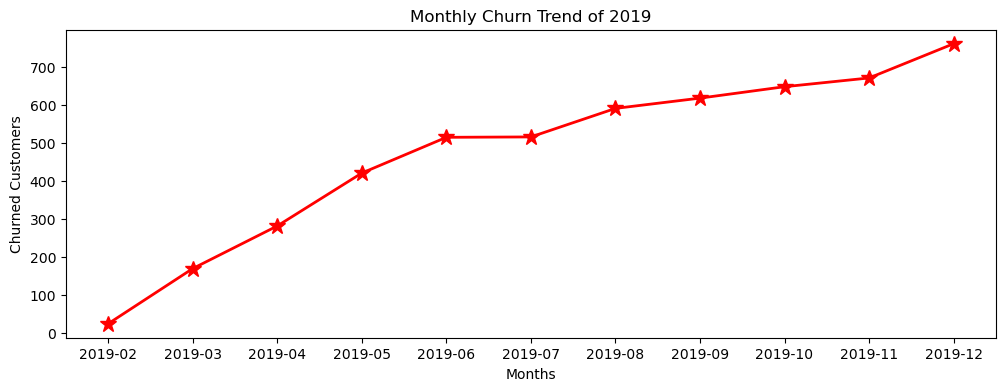

In [83]:
plt.figure(figsize = (12,4))
plt.plot(churn_trend.index.astype(str), churn_trend.values, color='red', marker='*', linestyle='-', linewidth=2, markersize=12)

plt.title(f"Monthly Churn Trend of {selected_year}")
plt.xlabel("Months")
plt.ylabel("Churned Customers")
plt.show()

---

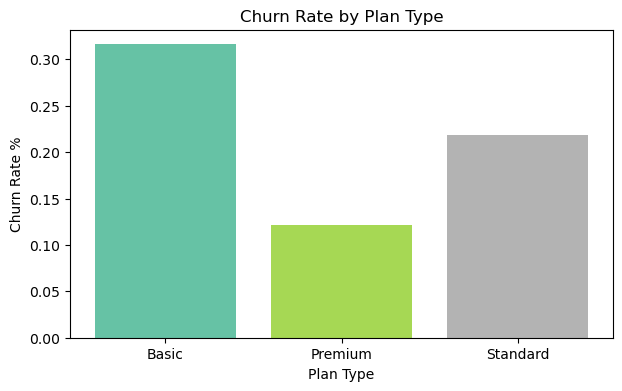

In [84]:
# 4.2 Churn Rate by Plan type
c = df_visuals.groupby("Plan_Type")["Churn_flag"].mean()

# rong = ["Red", "Purple", "Green"]   # Manual Method
rong = plt.cm.Set2(np.linspace(0, 1, len(c)))

plt.figure(figsize = (7,4))
plt.bar(c.index, c.values, color = rong)
plt.title("Churn Rate by Plan Type")
plt.xlabel("Plan Type")
plt.ylabel("Churn Rate %")
plt.show()

---

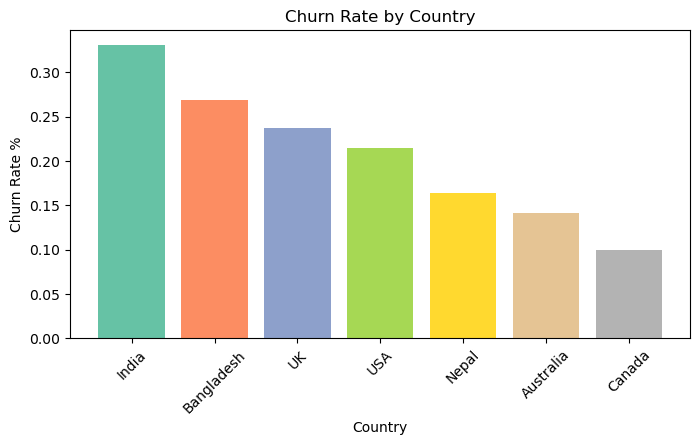

In [90]:
# 4.3 Churn by Country
c = df_visuals.groupby("Country")["Churn_flag"].mean()

# Sort churn rate from highest to lowest
c = c.sort_values(ascending=False)

# rong = ["Red", "Purple", "Green"]   # Manual Method
rong = plt.cm.Set2(np.linspace(0, 1, len(c)))

plt.figure(figsize = (8,4))
plt.bar(c.index, c.values, color = rong)
plt.title("Churn Rate by Country")
plt.xlabel("Country")
plt.ylabel("Churn Rate %")
plt.xticks(rotation=45)
plt.show()

---

In [87]:
# 4.4 Churn by States (Country-wise)

# Step 1: Select Country
selected_country = "India"    # Note: You can see the trend of all the States simply by changing the 'selected_country' variable..

# Step 2: Filter data for selected country
df_country = df_visuals[
    df_visuals["Country"].str.strip().str.lower() ==
    selected_country.lower()
].copy()

In [88]:
# Step 3: Calculate State-wise Churn Rate
cr = (
    df_country
    .groupby("State")["Churn_flag"].mean()*100
)

# Sort churn rate from highest to lowest
cr = cr.sort_values(ascending=False)

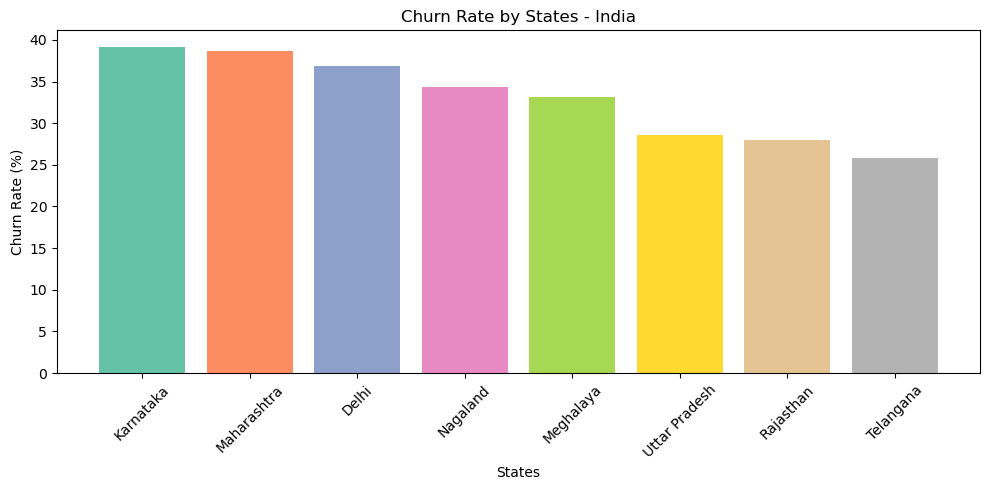

In [89]:
# Step 4: Generate colors
rong = plt.cm.Set2(np.linspace(0, 1, len(cr)))

# Step 5: Visualize
plt.figure(figsize=(10, 5))

plt.bar(cr.index, cr.values, color=rong)

plt.title(f"Churn Rate by States - {selected_country}")
plt.xlabel("States")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

---

## Visulaization using Seaborn

In [91]:
df_visuals.columns

Index(['Customerid', 'Subscription_Start_Date', 'Subscription_Type',
       'Renewal_Date', 'Plan_Type', 'Contract_Type', 'Cancellation_Date',
       'Cancellation_Reason', 'Monthly_Charges', 'Cltv', 'Churn_Score',
       'Churn_flag', 'Customer_name', 'Country', 'State', 'Gender', 'Dob',
       'Complaint_Date', 'Escalations', 'Csat_Score', 'Complaint_count',
       'Customer_age', 'tenure_days', 'Churn_risk', 'Cancellation_month'],
      dtype='object')

In [92]:
df_visuals[['Plan_Type', 'Contract_Type', 'Churn_Score', 'Churn_flag','Escalations','Churn_risk']].head()

,Plan_Type,Contract_Type,Churn_Score,Churn_flag,Escalations,Churn_risk
0,Basic,Monthly,0,0,0,Low
1,Premium,Annual,0,0,0,Low
2,Basic,Monthly,73,1,0,High
3,Standard,Monthly,26,0,0,Low
4,Basic,Annual,12,0,0,Low


In [93]:
df_visuals[['Plan_Type', 'Contract_Type', 'Churn_Score', 'Churn_flag','Escalations','Churn_risk']].tail()

,Plan_Type,Contract_Type,Churn_Score,Churn_flag,Escalations,Churn_risk
649995,Premium,Monthly,0,0,0,Low
649996,Basic,Monthly,25,0,0,Low
649997,Premium,Monthly,3,0,0,Low
649998,Basic,Annual,0,0,0,Low
649999,Basic,Monthly,88,1,0,High


In [94]:
# incorrect encoding - convert str to numeric so that we can find corr between features
df_encoded = df_visuals[['Plan_Type', 'Contract_Type', 'Churn_Score', 'Churn_flag','Escalations','Churn_risk']]

categorical_col = ["Plan_Type", "Contract_Type", "Churn_risk"]

for col in categorical_col:
    df_encoded[col] = df_encoded[col].astype("category").cat.codes

In [95]:
df_visuals[['Plan_Type', 'Contract_Type', 'Churn_Score', 'Churn_flag','Escalations','Churn_risk']].head()

,Plan_Type,Contract_Type,Churn_Score,Churn_flag,Escalations,Churn_risk
0,Basic,Monthly,0,0,0,Low
1,Premium,Annual,0,0,0,Low
2,Basic,Monthly,73,1,0,High
3,Standard,Monthly,26,0,0,Low
4,Basic,Annual,12,0,0,Low


In [96]:
df_encoded.head()

,Plan_Type,Contract_Type,Churn_Score,Churn_flag,Escalations,Churn_risk
0,0,1,0,0,0,1
1,1,0,0,0,0,1
2,0,1,73,1,0,0
3,2,1,26,0,0,1
4,0,0,12,0,0,1


<Axes: >

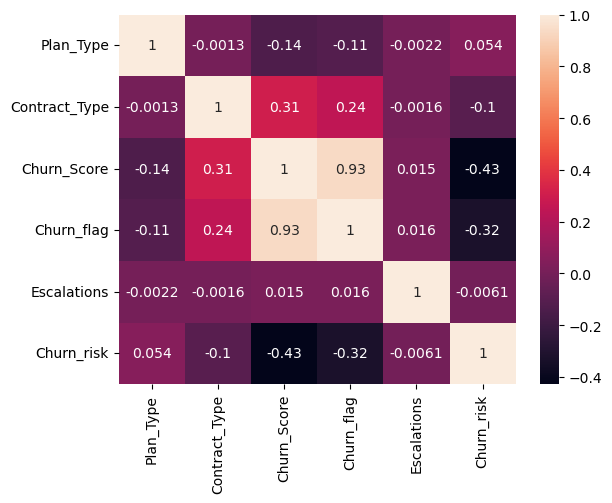

In [97]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot = True)

In [98]:
df_visuals["Churn_risk"].unique()

array(['Low', 'High', 'Medium'], dtype=object)

In [99]:
# correct method of encoding - based on priority

df_encoded = df_visuals[['Plan_Type', 'Contract_Type', 'Churn_Score', 'Churn_flag','Escalations','Churn_risk']]

order_mapping = {"Plan_Type" : ['Basic', 'Standard', 'Premium'],
                   "Contract_Type" : ['Monthly', 'Annual'],
                   "Churn_risk" : ['Low', 'Medium', 'High']}

for col, order in order_mapping.items():
    df_encoded[col] = pd.Categorical(df_encoded[col].astype("category"), categories = order, ordered = True).codes

In [100]:
df_visuals[['Plan_Type', 'Contract_Type', 'Churn_Score', 'Churn_flag','Escalations','Churn_risk']].head()

,Plan_Type,Contract_Type,Churn_Score,Churn_flag,Escalations,Churn_risk
0,Basic,Monthly,0,0,0,Low
1,Premium,Annual,0,0,0,Low
2,Basic,Monthly,73,1,0,High
3,Standard,Monthly,26,0,0,Low
4,Basic,Annual,12,0,0,Low


In [101]:
df_encoded.head()

,Plan_Type,Contract_Type,Churn_Score,Churn_flag,Escalations,Churn_risk
0,0,0,0,0,0,0
1,2,1,0,0,0,0
2,0,0,73,1,0,2
3,1,0,26,0,0,0
4,0,1,12,0,0,0


<Axes: >

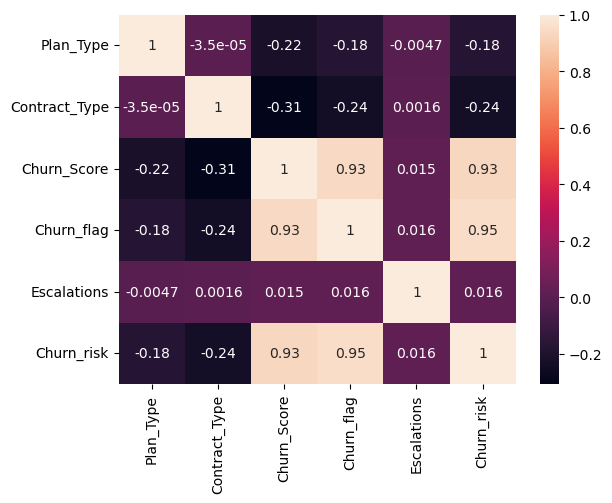

In [102]:
# Heatmap (correlation matrix)
sns.heatmap(df_encoded.corr(), annot = True)

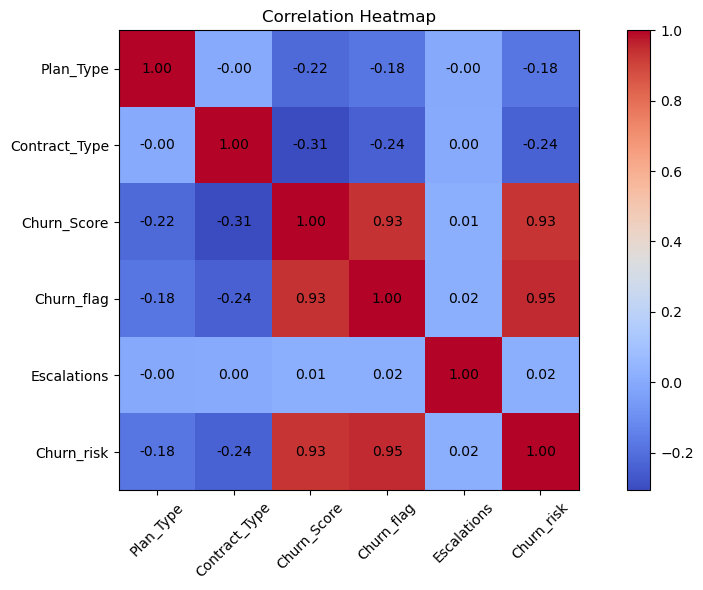

In [103]:
# Heatmap Using Matplotlib - difficult to plot it

corr_matrix = df_encoded.corr() # Correlation matrix

fig, ax = plt.subplots(figsize=(10, 6)) # Create figure

cax = ax.imshow(corr_matrix, cmap='coolwarm') # Heatmap

fig.colorbar(cax) # Add colorbar

# Axis labels
ax.set_xticks(np.arange(len(corr_matrix.columns)))
ax.set_yticks(np.arange(len(corr_matrix.columns)))

ax.set_xticklabels(corr_matrix.columns, rotation=45)
ax.set_yticklabels(corr_matrix.columns)

# Annotate values inside cells
for i in range(len(corr_matrix.columns)):
    for j in range(len(corr_matrix.columns)):
        ax.text(
            j,
            i,
            f"{corr_matrix.iloc[i, j]:.2f}",
            ha='center',
            va='center'
        )

plt.title('Correlation Heatmap') # Title

plt.tight_layout()
plt.show()

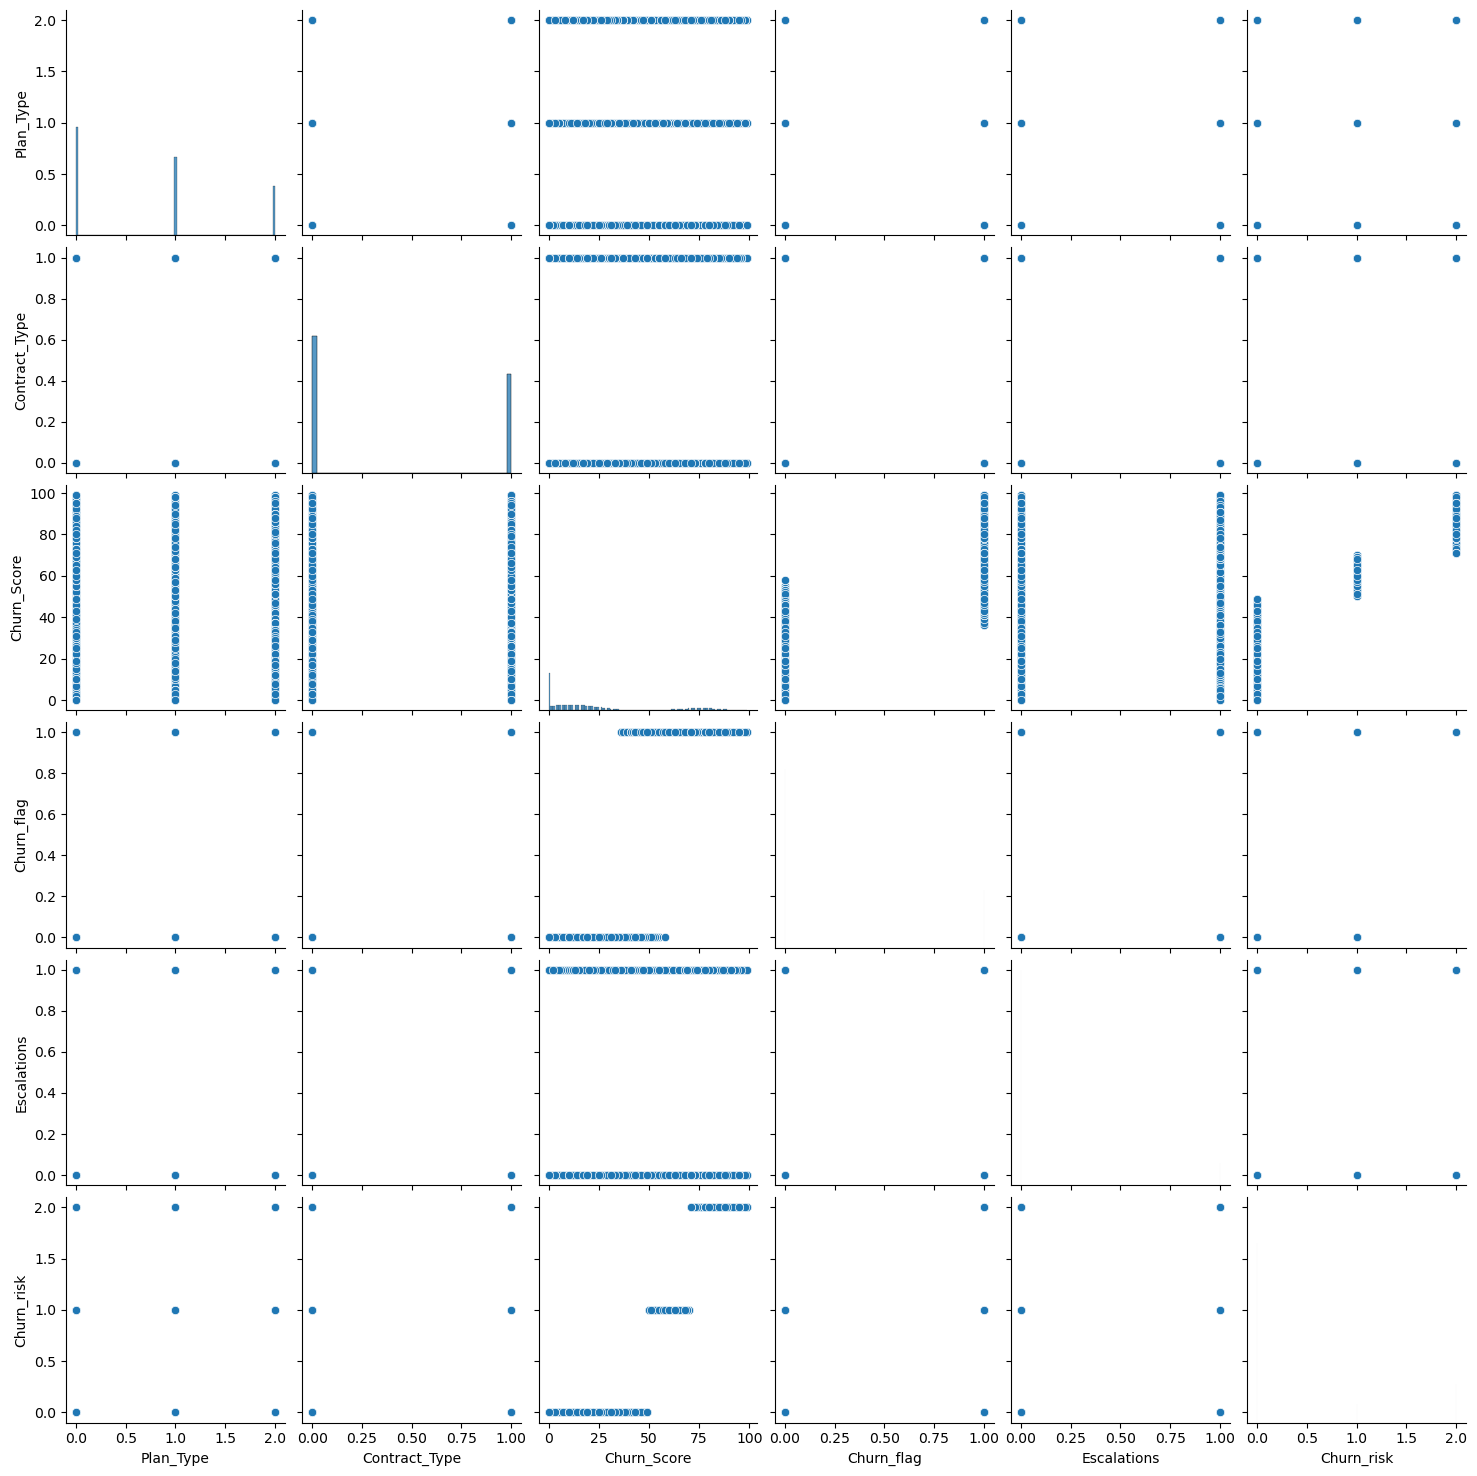

In [104]:
# pairplot - Plot pairwise relationships in a dataset
sns.pairplot(df_encoded)

In [105]:
df_visuals.columns

Index(['Customerid', 'Subscription_Start_Date', 'Subscription_Type',
       'Renewal_Date', 'Plan_Type', 'Contract_Type', 'Cancellation_Date',
       'Cancellation_Reason', 'Monthly_Charges', 'Cltv', 'Churn_Score',
       'Churn_flag', 'Customer_name', 'Country', 'State', 'Gender', 'Dob',
       'Complaint_Date', 'Escalations', 'Csat_Score', 'Complaint_count',
       'Customer_age', 'tenure_days', 'Churn_risk', 'Cancellation_month'],
      dtype='object')

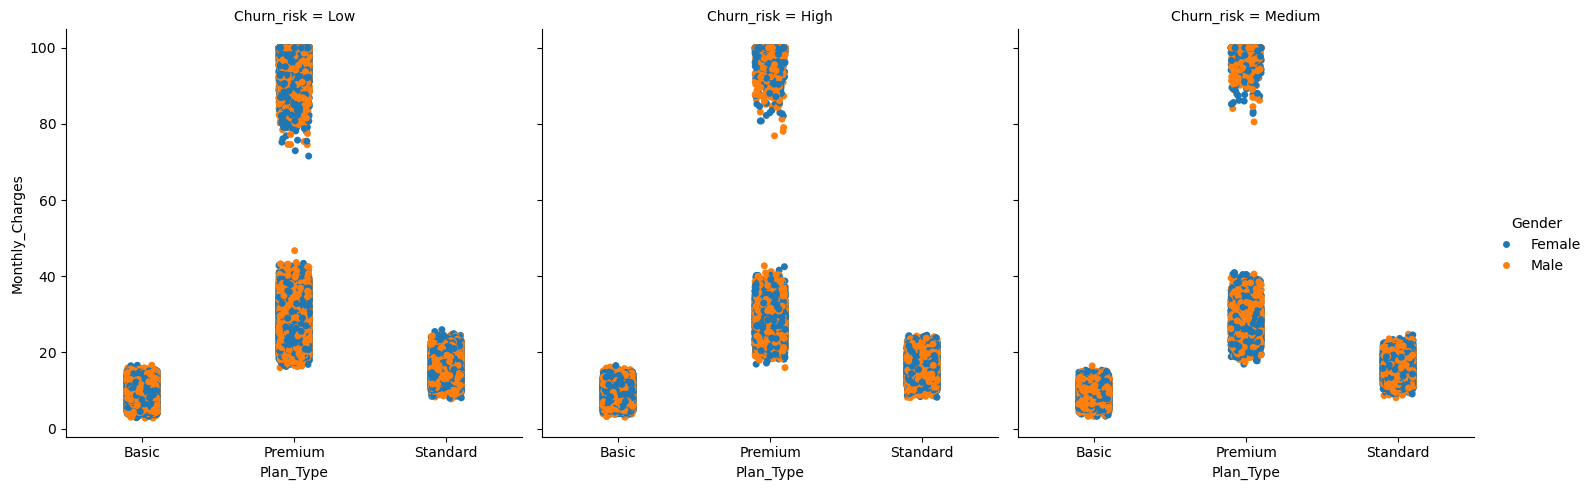

In [106]:
# catplt/Facegrid plot - multi-dim comparison
sns.catplot(df_visuals,
            x='Plan_Type',
            y='Monthly_Charges',
            hue='Gender',
            col='Churn_risk',
            )

## Pivot table

In [107]:
df_visuals.columns

Index(['Customerid', 'Subscription_Start_Date', 'Subscription_Type',
       'Renewal_Date', 'Plan_Type', 'Contract_Type', 'Cancellation_Date',
       'Cancellation_Reason', 'Monthly_Charges', 'Cltv', 'Churn_Score',
       'Churn_flag', 'Customer_name', 'Country', 'State', 'Gender', 'Dob',
       'Complaint_Date', 'Escalations', 'Csat_Score', 'Complaint_count',
       'Customer_age', 'tenure_days', 'Churn_risk', 'Cancellation_month'],
      dtype='object')

In [108]:
# Pivot Table
pd.pivot_table(df_visuals,
              index = 'Plan_Type',
              values = 'Churn_flag',
              aggfunc = 'mean')

,Churn_flag
Plan_Type,
Basic,0.316149
Premium,0.121030
Standard,0.218803


In [109]:
# Reseting the index of that Pivot Table
pd.pivot_table(df_visuals,
              index = 'Plan_Type',
              values = 'Churn_flag',
              aggfunc = 'mean').reset_index()

,Plan_Type,Churn_flag
0,Basic,0.316149
1,Premium,0.121030
2,Standard,0.218803


In [110]:
# pivot table using multiple cols and agg type
pd.pivot_table(df_visuals,
              index = 'Plan_Type',
              values = ['Customerid', 'Monthly_Charges', 'Churn_flag', 'Country'],
              aggfunc = {
                  'Customerid' : 'nunique',
                  'Monthly_Charges' : 'sum',
                  'Churn_flag' : 'mean',
                  'Country' : 'nunique'
              })

,Churn_flag,Country,Customerid,Monthly_Charges
Plan_Type,,,,
Basic,0.316149,7,161426,2647292.37
Premium,0.121030,7,101399,5378869.85
Standard,0.218803,7,136210,3357795.49
